In [2]:
import pandas as pd

In [20]:
Walmart = pd.read_csv("Walmart.csv")

Walmart.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [21]:
Walmart.info()

<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   str    
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), str(1)
memory usage: 402.3 KB


In [22]:
Walmart.describe(include="all")

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6435,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
unique,NaN,143,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,05-02-2010,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,45,NaN,NaN,NaN,NaN,NaN,NaN
mean,23.000000,NaN,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,NaN,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,NaN,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,NaN,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,NaN,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,NaN,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000


In [23]:
missing_values = Walmart.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [24]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [25]:
numeric_features = Walmart[less].select_dtypes(include=['number']).columns

Walmart[numeric_features] = Walmart[numeric_features].fillna(
    Walmart[numeric_features].median()
)

In [26]:
categorical_features = Walmart[less].select_dtypes(include=['object']).columns

for column in categorical_features:
    Walmart[column] = Walmart[column].fillna(Walmart[column].mode()[0])

C:\Users\Ahmad Raja\AppData\Local\Temp\ipykernel_18956\1190378492.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = Walmart[less].select_dtypes(include=['object']).columns


In [27]:
df = Walmart.drop(columns=over)

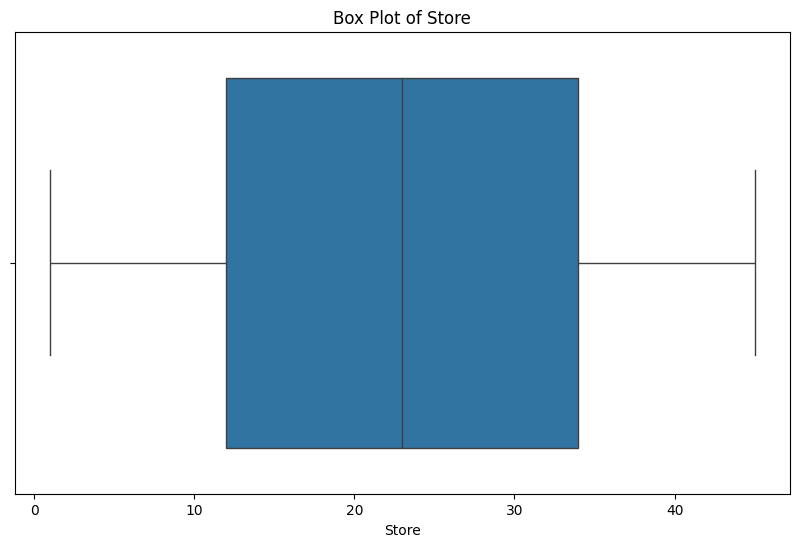

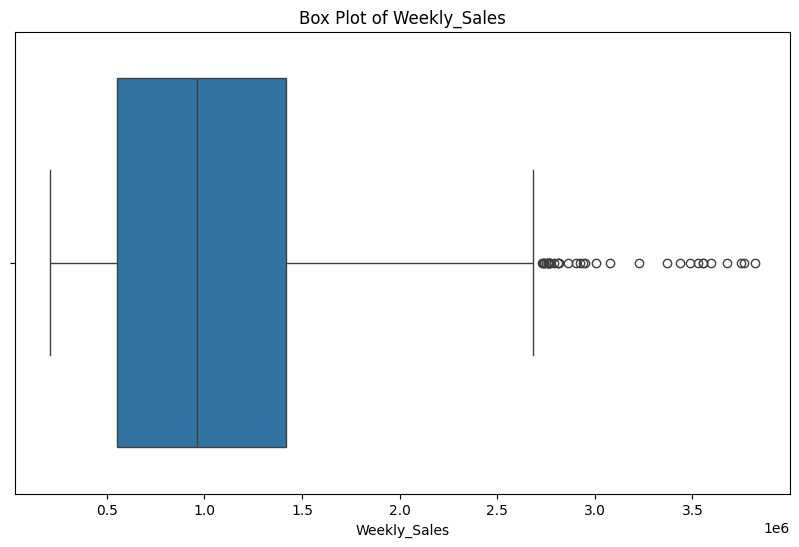

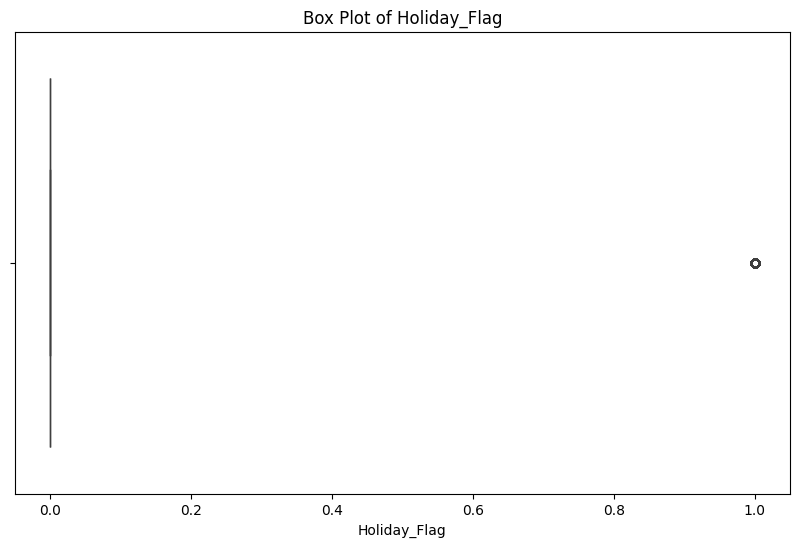

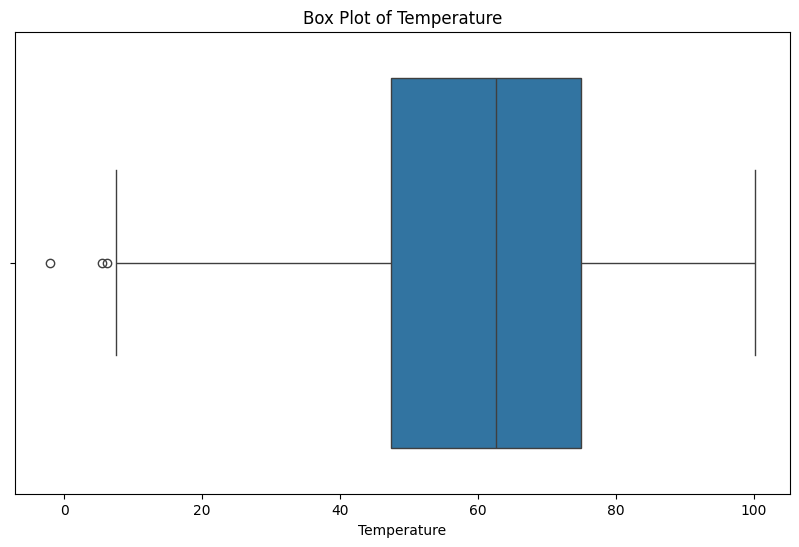

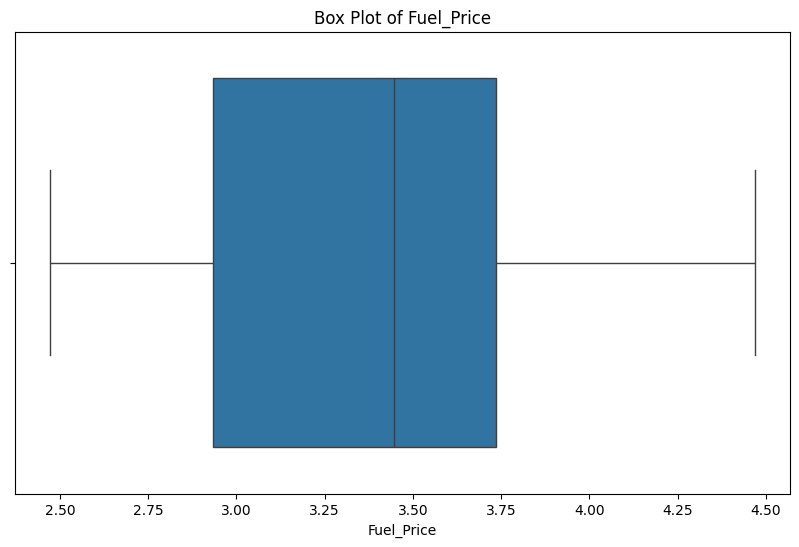

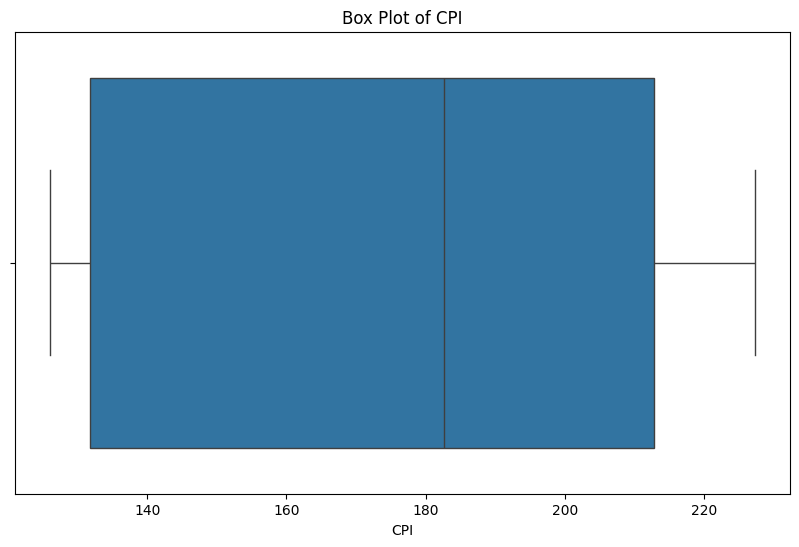

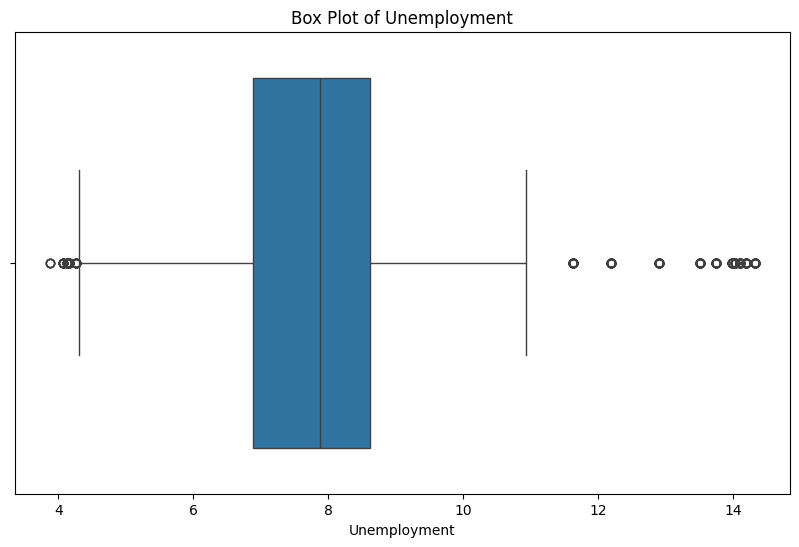

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [30]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [31]:
condition = (
    (df[numeric_features] < (Q1 - 1.5 * IQR)) |
    (df[numeric_features] > (Q3 - 1.5 * IQR))
).any(axis=1)

df_filtered_numeric = df.loc[condition, numeric_features]

categorical_features = df.select_dtypes(include=['object']).columns

df = pd.concat(
    [df_filtered_numeric, df.loc[condition, categorical_features]],
    axis=1
)

C:\Users\Ahmad Raja\AppData\Local\Temp\ipykernel_18956\1868069527.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


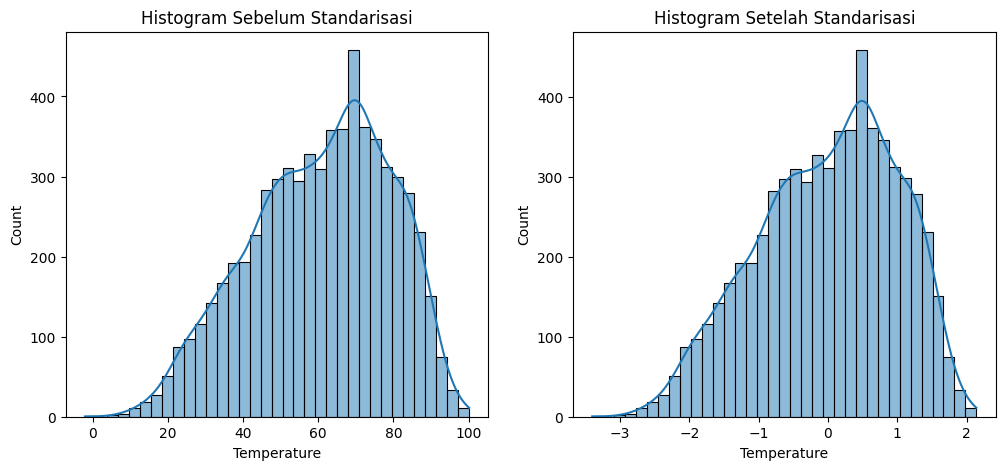

In [33]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(Walmart[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standarisasi")
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standarisasi")
plt.show()



In [34]:
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])


Baris duplikat:
Empty DataFrame
Columns: [Store, Weekly_Sales, Holiday_Flag, Temperature, Fuel_Price, CPI, Unemployment, Date]
Index: []


In [35]:
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
         Store  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price       CPI  \
0    -1.693979      1.057420     -0.274204    -0.995136   -1.713800  1.004175   
1    -1.693979      1.054348      3.646917    -1.201170   -1.766089  1.007880   
2    -1.693979      1.001206     -0.274204    -1.124178   -1.840166  1.009074   
3    -1.693979      0.642828     -0.274204    -0.760907   -1.737766  1.009849   
4    -1.693979      0.899914     -0.274204    -0.767955   -1.598328  1.010624   
...        ...           ...           ...          ...         ...       ...   
6430  1.693979     -0.591489     -0.274204     0.228602    1.390883  0.519270   
6431  1.693979     -0.555551     -0.274204     0.229144    1.364738  0.523256   
6432  1.693979     -0.553762     -0.274204    -0.335825    1.397419  0.527241   
6433  1.693979     -0.582715     -0.274204    -0.227385    1.329879  0.527332   
6434  1.693979     -0.508013     -0.274204    -0.098343    1.140330  0.

In [36]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

C:\Users\Ahmad Raja\AppData\Local\Temp\ipykernel_18956\2319133481.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,Date
0,05-02-2010
1,12-02-2010
2,19-02-2010
3,26-02-2010
4,05-03-2010
...,...
6430,28-09-2012
6431,05-10-2012
6432,12-10-2012
6433,19-10-2012


In [37]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Date_01-04-2011,Date_01-06-2012,Date_01-07-2011,...,Date_29-06-2012,Date_29-07-2011,Date_29-10-2010,Date_30-03-2012,Date_30-04-2010,Date_30-07-2010,Date_30-09-2011,Date_30-12-2011,Date_31-08-2012,Date_31-12-2010
0,-1.693979,1.057420,-0.274204,-0.995136,-1.713800,1.004175,0.056964,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,-1.693979,1.054348,3.646917,-1.201170,-1.766089,1.007880,0.056964,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,-1.693979,1.001206,-0.274204,-1.124178,-1.840166,1.009074,0.056964,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,-1.693979,0.642828,-0.274204,-0.760907,-1.737766,1.009849,0.056964,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,-1.693979,0.899914,-0.274204,-0.767955,-1.598328,1.010624,0.056964,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6430,1.693979,-0.591489,-0.274204,0.228602,1.390883,0.519270,0.365109,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6431,1.693979,-0.555551,-0.274204,0.229144,1.364738,0.523256,0.356046,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6432,1.693979,-0.553762,-0.274204,-0.335825,1.397419,0.527241,0.356046,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6433,1.693979,-0.582715,-0.274204,-0.227385,1.329879,0.527332,0.356046,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [38]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

df_lencoder

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Date
0,-1.693979,1.057420,-0.274204,-0.995136,-1.713800,1.004175,0.056964,19
1,-1.693979,1.054348,3.646917,-1.201170,-1.766089,1.007880,0.056964,52
2,-1.693979,1.001206,-0.274204,-1.124178,-1.840166,1.009074,0.056964,85
3,-1.693979,0.642828,-0.274204,-0.760907,-1.737766,1.009849,0.056964,118
4,-1.693979,0.899914,-0.274204,-0.767955,-1.598328,1.010624,0.056964,20
...,...,...,...,...,...,...,...,...
6430,1.693979,-0.591489,-0.274204,0.228602,1.390883,0.519270,0.365109,130
6431,1.693979,-0.555551,-0.274204,0.229144,1.364738,0.523256,0.356046,22
6432,1.693979,-0.553762,-0.274204,-0.335825,1.397419,0.527241,0.356046,55
6433,1.693979,-0.582715,-0.274204,-0.227385,1.329879,0.527332,0.356046,88


In [39]:
#Praktek EDA dan ExDA
df_lencoder.head()


,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Date
0,-1.693979,1.057420,-0.274204,-0.995136,-1.713800,1.004175,0.056964,19
1,-1.693979,1.054348,3.646917,-1.201170,-1.766089,1.007880,0.056964,52
2,-1.693979,1.001206,-0.274204,-1.124178,-1.840166,1.009074,0.056964,85
3,-1.693979,0.642828,-0.274204,-0.760907,-1.737766,1.009849,0.056964,118
4,-1.693979,0.899914,-0.274204,-0.767955,-1.598328,1.010624,0.056964,20


In [40]:
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) *100

missing_data = pd.DataFrame({
    'Missing_Values': missing_values,
    'Percentage': missing_percentage 
}).sort_values(by='Missing_Values', ascending=False)

missing_data[missing_data['Missing_Values']> 0]

,Missing_Values,Percentage


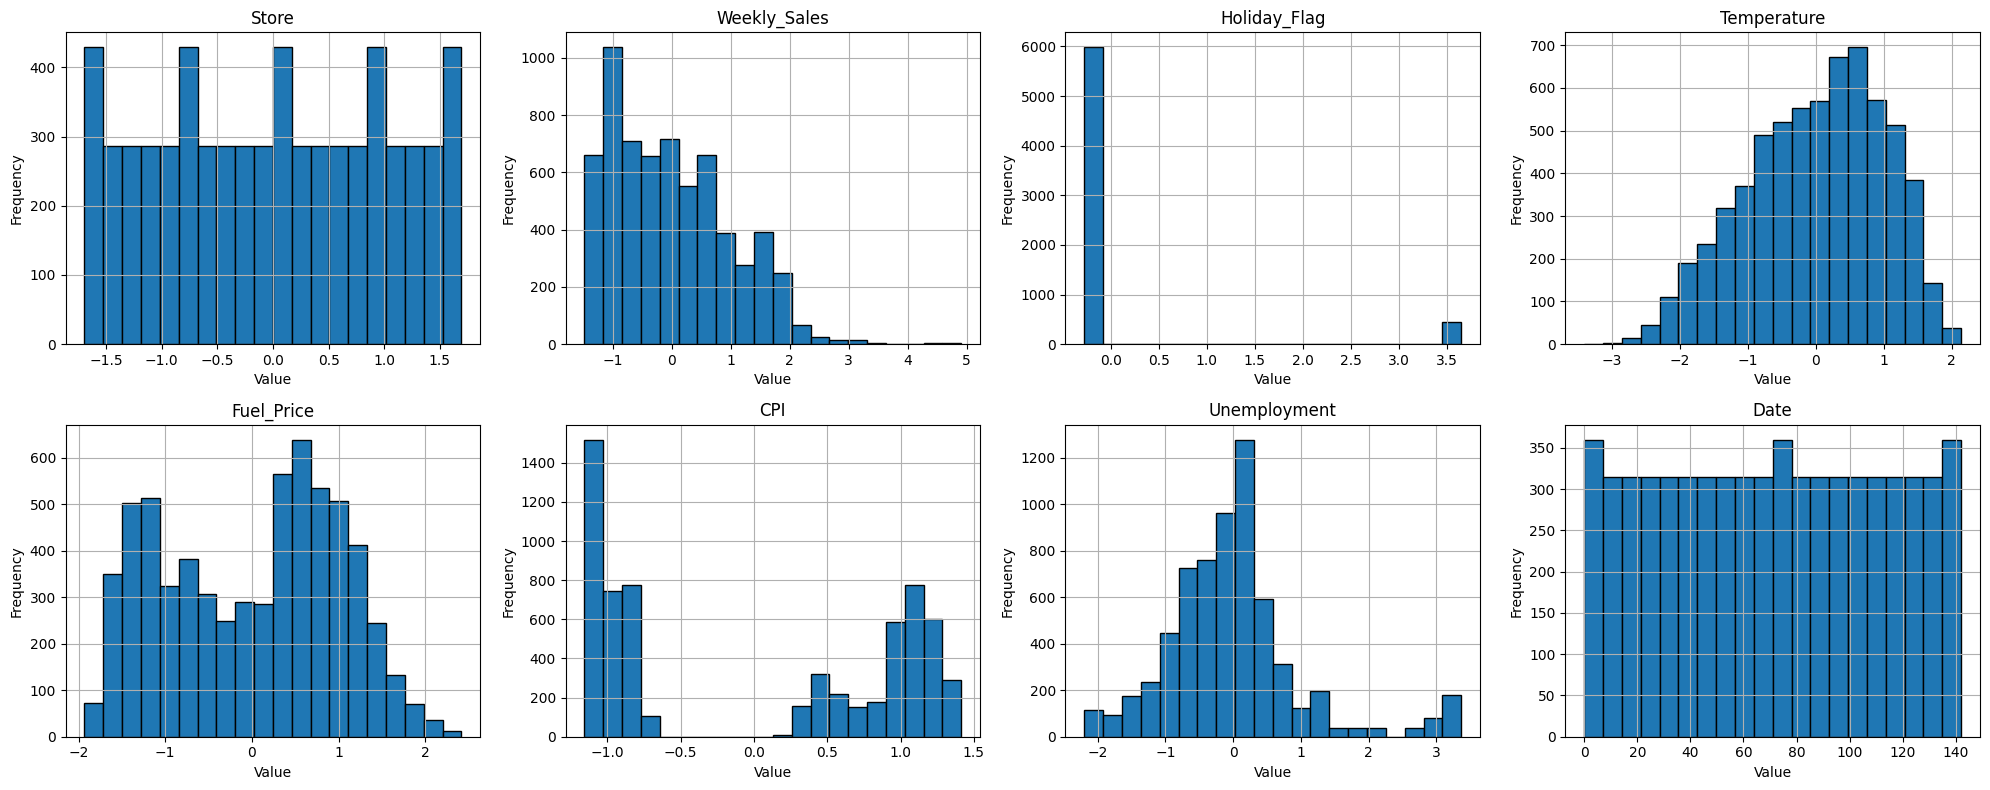

In [41]:
num_vars = df_lencoder.shape[1]

n_cols = 4
n_rows = -(-num_vars // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()


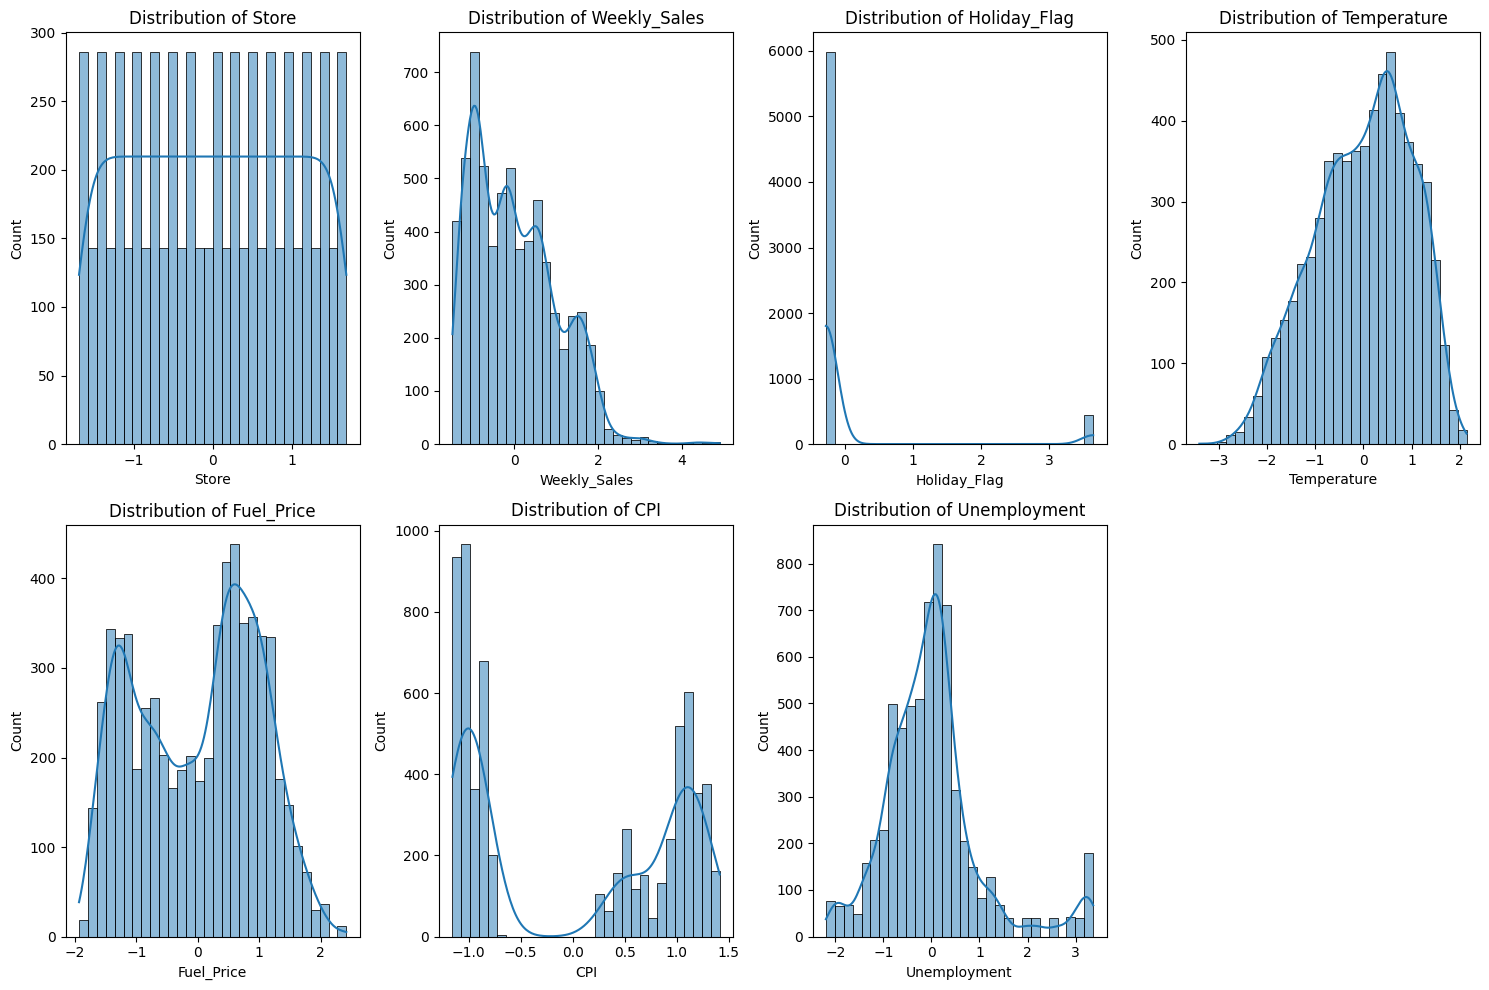

In [43]:
columns_to_plot = [
    'Store',
    'Weekly_Sales',
    'Holiday_Flag',
    'Temperature',
    'Fuel_Price',
    'CPI',
    'Unemployment'
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(columns_to_plot, 1):

    plt.subplot(2, 4, i)

    sns.histplot(
        df_lencoder[column],
        kde=True,
        bins=30
    )

    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

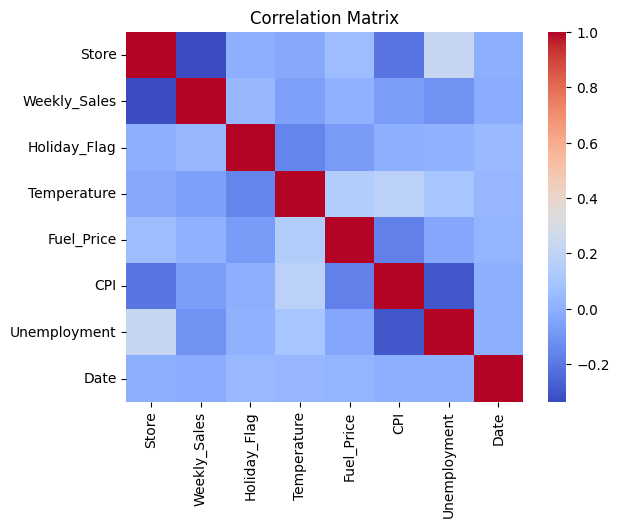

In [44]:
plt.Figure(figsize=(12,10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmax=1)
plt.title('Correlation Matrix')
plt.show()

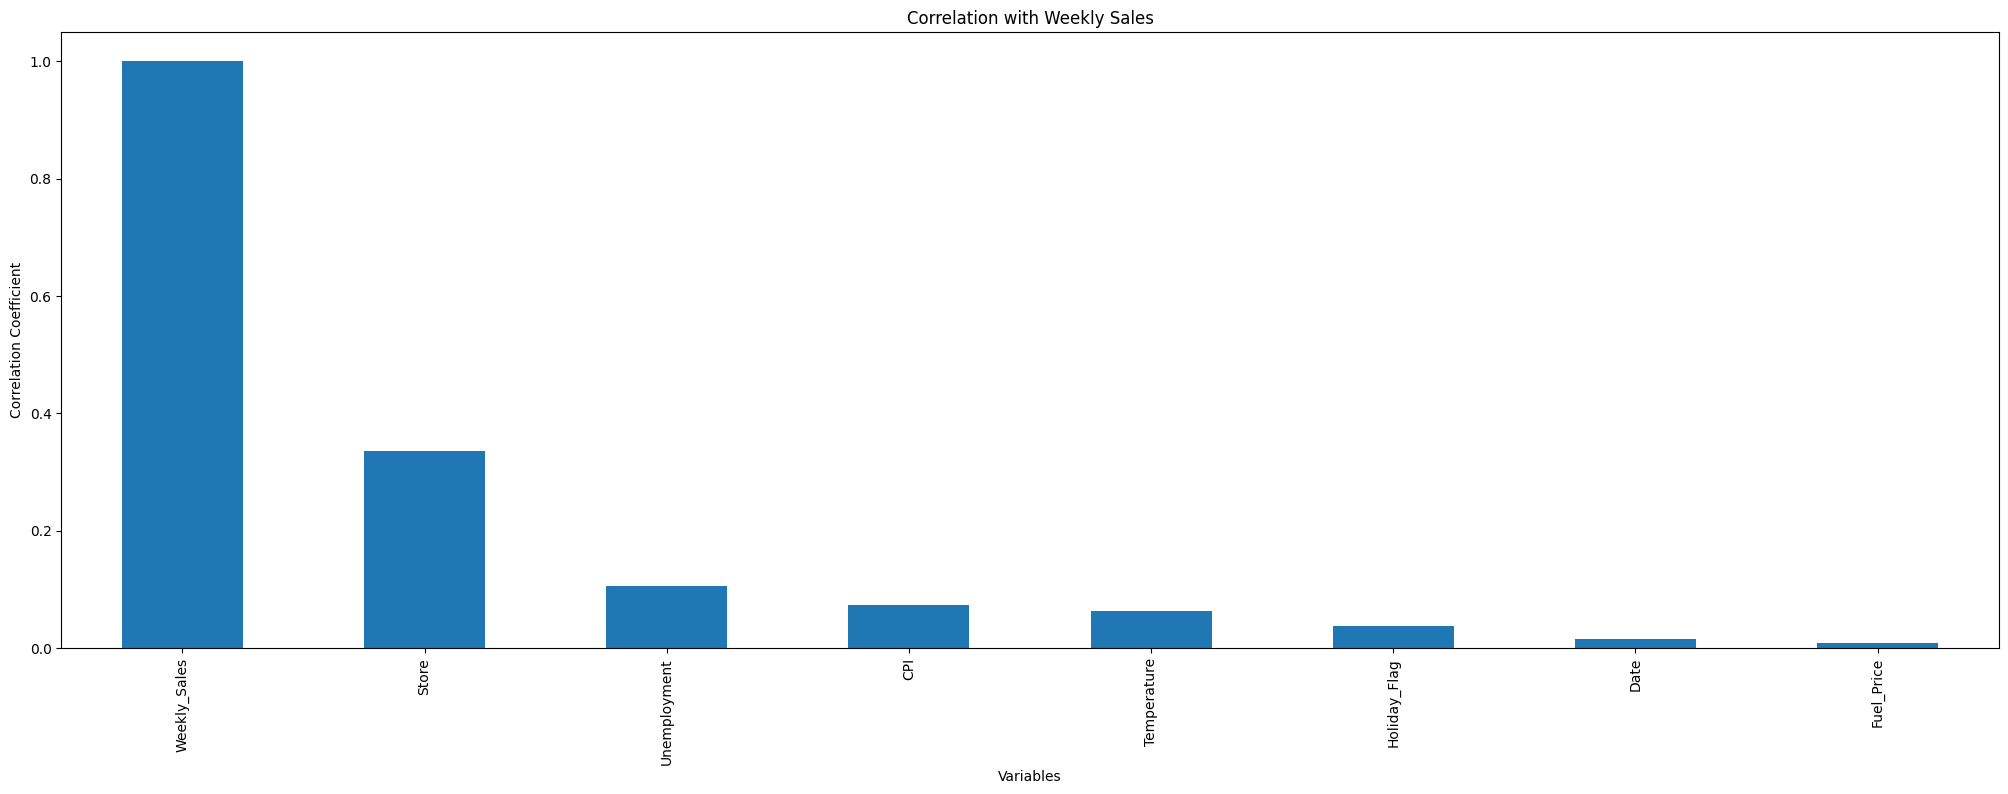

In [45]:
target_corr = df_lencoder.corr()['Weekly_Sales']

target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(25, 8))

target_corr_sorted.plot(kind='bar')

plt.title('Correlation with Weekly Sales')

plt.xlabel('Variables')

plt.ylabel('Correlation Coefficient')

plt.show()